# scooby bridge — single-cell sequence→profile on Epione data

`epione.models.scooby` is a **bridge** to
[scooby](https://github.com/gagneurlab/scooby) (Hingerl, Martens *et al.*,
*Nat Methods* 2026), the published baseline for predicting single-cell
ATAC/RNA profiles from DNA sequence. It is not a reimplementation:
upstream's model and loss are imported unchanged and only the data path
is Epione's, so results stay comparable with upstream's.

This notebook runs the whole path on **real spatial ATAC** — sample
`P2S1` of GSE308623 (mouse brain, postnatal day 2, 100×100 spot grid,
mm10) — and ends by driving upstream's `Scooby` on pretrained Borzoi
weights.

What it shows:

* `epi.models.scooby.FragmentInsertionReader` — Tn5 insertion targets read
  straight from a tabix-indexed fragments file, replacing upstream's
  genome-wide `cells × base-pair` matrix.
* `expected_fragments_per_window` — the measurement that decides whether
  per-cell targets are viable at all. On this data they are not.
* `make_fold_bed` — cross-validation folds that cannot leak, which random
  window assignment does.
* `load_scooby` — constructing the upstream model so it can actually be
  moved to a GPU.

### What the bridge drops

Upstream needs four awkward dependencies that this path does not:
the forked `snapatac2-scooby` (for the genome-wide insertion matrix),
`enformer_pytorch`'s data loader, `pybigtools` (a Rust build), and a
second conda environment because of a numpy pin. Reading windows on
demand removes the first two; the last two were only ever needed by the
parts removed. The bridge itself imports only numpy, pandas, pysam and
torch, so it also runs in a lean torch environment without Epione's full
analysis stack. This notebook additionally calls `epi.pl.plot_set()` for
the figure style shared by all tutorials, which needs the full install.

## Part 1 · Setup

### Getting the inputs

Three downloads, into whatever directory `SCOOBY_TUTORIAL_DATA` points at
(it defaults to the directory above the repo):

```bash
DATA=${SCOOBY_TUTORIAL_DATA:-..}
mkdir -p $DATA/scooby_bench $DATA/genome/mm10

# 1. The sample — GEO GSE308623, spatial ATAC of mouse brain at P2.
#    Fragments, its tabix index, and the spot position list.
cd $DATA/scooby_bench
for f in GSM9248994_01_P2S1_atac_fragments.tsv.gz \
         GSM9248994_01_P2S1_atac_fragments.tsv.gz.tbi.gz \
         GSM9247578_01_P2S1_tissue_positions_list.csv.gz; do
  curl -O "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9248nnn/${f%%_*}/suppl/$f"
done
mv GSM9248994_01_P2S1_atac_fragments.tsv.gz  P2S1.fragments.tsv.gz
gunzip -c GSM9248994_01_P2S1_atac_fragments.tsv.gz.tbi.gz > P2S1.fragments.tsv.gz.tbi
gunzip -c GSM9247578_01_P2S1_tissue_positions_list.csv.gz > P2S1.positions.csv

# 2. Reference sequence — only chr19 is needed here (~62 MB).
cd $DATA/genome/mm10
curl -O https://hgdownload.soe.ucsc.edu/goldenPath/mm10/chromosomes/chr19.fa.gz
gunzip -f chr19.fa.gz
curl -O https://hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.chrom.sizes
```

Part 6 additionally needs upstream scooby on `SCOOBY_SRC`
(`git clone https://github.com/gagneurlab/scooby`) and a GPU. It skips
cleanly if either is absent.

In [1]:
import os, sys, pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


# Walk up until the directory holding the epione package.
def _find_repo(start):
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


# Works whether epione is pip-installed or used from the source tree.
CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

from epione.models import scooby as sb

DATA   = pathlib.Path(os.environ.get('SCOOBY_TUTORIAL_DATA',
                                     (CODE or pathlib.Path.cwd()).parent))
WORK   = DATA / 'scooby_bench'
GENOME = DATA / 'genome' / 'mm10'

FRAG   = WORK / 'P2S1.fragments.tsv.gz'
POS    = WORK / 'P2S1.positions.csv'
FASTA  = GENOME / 'chr19.fa'
SIZES  = GENOME / 'mm10.chrom.sizes'

CHROM  = 'chr19'
for p in (FRAG, POS, FASTA, SIZES):
    if not p.exists():
        raise FileNotFoundError(f'{p} — see "Getting the inputs" above')

print('bridge exports:', len(sb.__all__), 'symbols')
print('geometry: input', sb.INPUT_LENGTH, 'bp -> target', sb.TARGET_LENGTH,
      f'bp ({sb.TARGET_LENGTH // 32} bins of 32 bp), flank {sb.FLANK} bp')

bridge exports: 21 symbols
geometry: input 524288 bp -> target 196608 bp (6144 bins of 32 bp), flank 163840 bp


In [2]:
%matplotlib inline
import epione as epi

epi.pl.plot_set()

# Categorical colours: distinct hues from epione's palette, in a fixed
# order. Bands use the first four, folds all eight.
FOLD_C = [epi.pl.sc_color[i] for i in (7, 6, 13, 11, 5, 1, 15, 18)]
C = FOLD_C[:4]   # blue, coral, purple, green
# Magnitude: a single-hue light-to-dark ramp.
SEQ = LinearSegmentedColormap.from_list(
    'blues', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

.../site-packages/torch/cuda/__init__.py:65: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: unknown   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Part 2 · The sample

Each 50 µm spot of the grid is one barcode in the fragments file. The
tissue-position list says which spots sit on tissue; those are the cells
the reader is indexed by.

In [3]:
pos = pd.read_csv(
    POS, header=None,
    names=['barcode', 'in_tissue', 'array_row', 'array_col', 'px_row', 'px_col'],
)
in_tissue = pos[pos['in_tissue'] == 1].reset_index(drop=True)
print(f'{len(pos):,} spots on the grid, {len(in_tissue):,} on tissue')

chrom_sizes = dict(
    pd.read_csv(SIZES, sep='\t', header=None, names=['chrom', 'length'])
      .itertuples(index=False, name=None)
)

# Fragments carry a '-1' suffix the position list drops.
reader = sb.FragmentInsertionReader(
    FRAG, in_tissue['barcode'].tolist(),
    chrom_sizes=chrom_sizes, barcode_suffix='-1',
)
reader

10,000 spots on the grid, 7,131 on tissue


FragmentInsertionReader(P2S1.fragments.tsv.gz, n_cells=7131)

In [4]:
%%time
# Per-spot depth on chr19 only: enough for a spatial QC view, and fast.
import pysam
bc_to_idx = {b + '-1': i for i, b in enumerate(reader.barcodes)}
depth = np.zeros(reader.n_cells, dtype=np.int64)
tbx = pysam.TabixFile(str(FRAG))
n_frag = 0
for line in tbx.fetch(CHROM):
    i = bc_to_idx.get(line.split('\t', 4)[3])
    if i is not None:
        depth[i] += 1
        n_frag += 1
tbx.close()
print(f'{n_frag:,} chr19 fragments in tissue spots')
print(f'per-spot chr19 depth: median {np.median(depth):,.0f}  '
      f'IQR {np.percentile(depth, 25):,.0f}-{np.percentile(depth, 75):,.0f}')

2,856,209 chr19 fragments in tissue spots
per-spot chr19 depth: median 371  IQR 256-510
CPU times: user 2.6 s, sys: 7.58 ms, total: 2.6 s
Wall time: 2.6 s


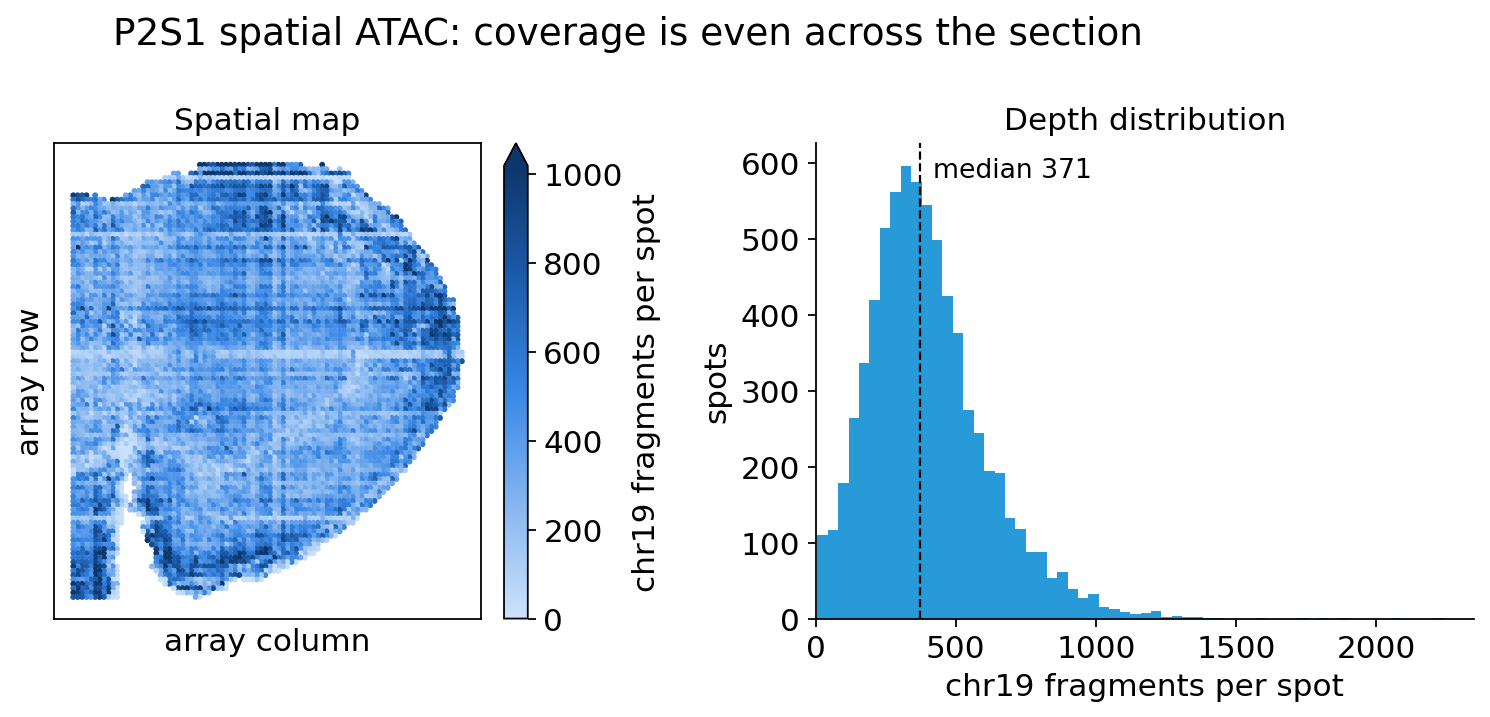

In [5]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.6),
                              gridspec_kw={'width_ratios': [1.15, 1]})

# Cap the colour scale at the 99th percentile so a few very deep spots do
# not wash out the rest of the section; the arrow on the bar marks the cap.
vmax = float(np.percentile(depth, 99))
sc = ax.scatter(in_tissue['array_col'], in_tissue['array_row'],
                c=depth, s=7, cmap=SEQ, vmin=0, vmax=vmax, linewidths=0)
ax.set_aspect('equal'); ax.invert_yaxis()
ax.set_title('Spatial map')
ax.set_xlabel('array column'); ax.set_ylabel('array row')
ax.set_xticks([]); ax.set_yticks([])
cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.03, extend='max')
cb.set_label('chr19 fragments per spot')

ax2.hist(depth, bins=60, color=C[0], edgecolor='none')
ax2.axvline(np.median(depth), color='k', lw=1.0, ls='--')
ax2.annotate(f'median {np.median(depth):,.0f}',
             xy=(np.median(depth), ax2.get_ylim()[1] * 0.97),
             xytext=(6, 0), textcoords='offset points', fontsize=12, va='top')
ax2.set_title('Depth distribution')
ax2.set_xlabel('chr19 fragments per spot'); ax2.set_ylabel('spots')
ax2.set_xlim(0, None)
ax2.spines[['top', 'right']].set_visible(False)

fig.suptitle('P2S1 spatial ATAC: coverage is even across the section')
plt.tight_layout(); plt.show()

## Part 3 · Why targets must be grouped

A spot's depth looks healthy — but the model predicts a **196,608 bp
window**, which is a 14,000th of the genome. The quantity that matters is
how many fragments a group puts *into one window*.

`expected_fragments_per_window` answers it before any training is
attempted.

In [6]:
# Scale the measured chr19 depth to the whole genome.
genome_len = sum(v for k, v in chrom_sizes.items() if '_' not in k)
per_cell_genome = float(np.median(depth)) * genome_len / chrom_sizes[CHROM]
print(f'median depth, genome-wide equivalent: {per_cell_genome:,.0f} fragments/spot')

for n in (1, 10, 100, 1000, len(in_tissue)):
    e = sb.expected_fragments_per_window(per_cell_genome, genome_len, n)
    print(f'  {n:>5,} spot(s) -> {e:>9,.1f} fragments per 196 kb window')

median depth, genome-wide equivalent: 16,460 fragments/spot
      1 spot(s) ->       1.2 fragments per 196 kb window
     10 spot(s) ->      11.9 fragments per 196 kb window
    100 spot(s) ->     118.7 fragments per 196 kb window
  1,000 spot(s) ->   1,187.4 fragments per 196 kb window
  7,131 spot(s) ->   8,467.1 fragments per 196 kb window


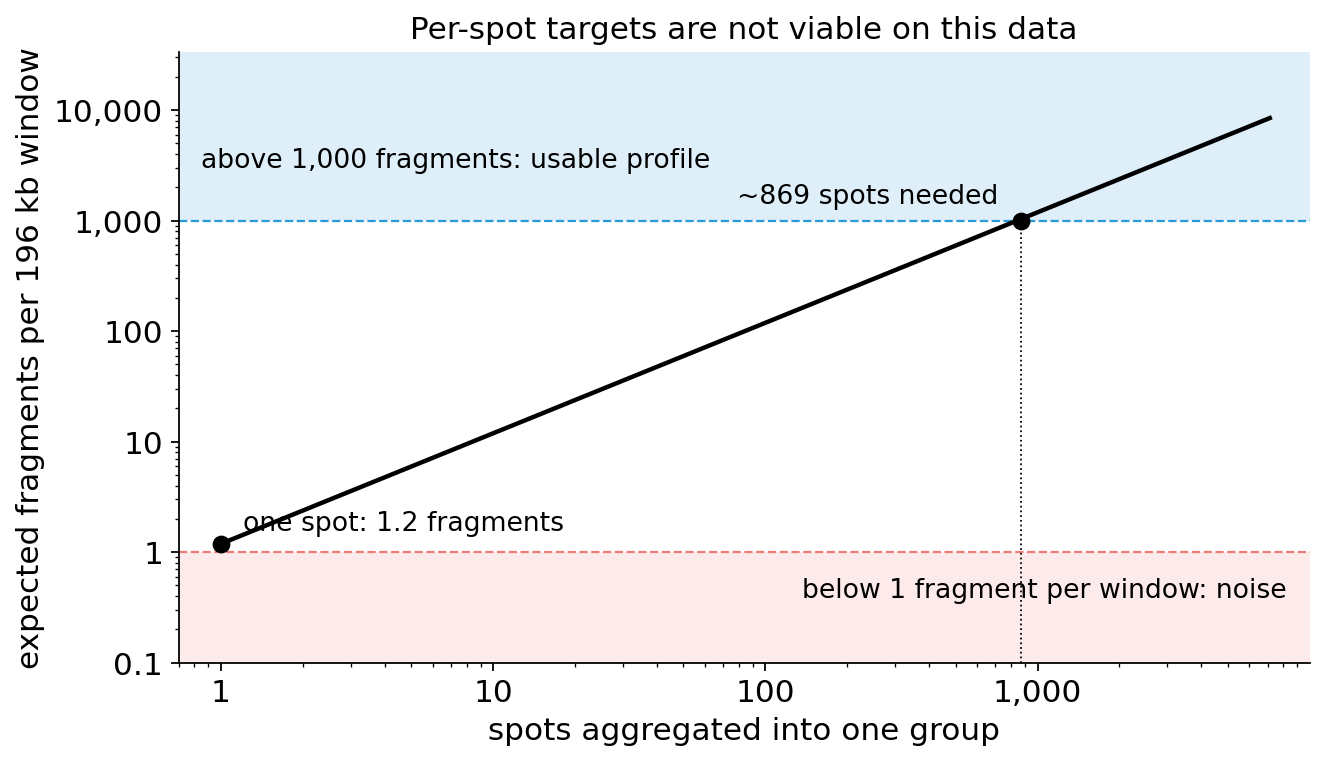

In [7]:
sizes = np.unique(np.clip(np.round(np.logspace(0, np.log10(len(in_tissue)), 60)),
                          1, None).astype(int))
exp = np.array([sb.expected_fragments_per_window(per_cell_genome, genome_len, n)
                for n in sizes])

from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(8.5, 5))
ylo, yhi = 0.1, exp.max() * 4
# Shaded zones span the whole frame; their labels sit inside them.
ax.axhspan(ylo, 1, color=C[1], alpha=0.15, lw=0)
ax.axhspan(1e3, yhi, color=C[0], alpha=0.15, lw=0)
ax.axhline(1, color=C[1], lw=1, ls='--')
ax.axhline(1e3, color=C[0], lw=1, ls='--')
ax.annotate('below 1 fragment per window: noise', xy=(0.98, 0.45),
            xycoords=('axes fraction', 'data'), ha='right', va='center',
            fontsize=12)
ax.annotate('above 1,000 fragments: usable profile', xy=(0.02, 3.5e3),
            xycoords=('axes fraction', 'data'), ha='left', va='center',
            fontsize=12)

# The curve is drawn dark so it stands apart from the light blue zone.
ax.loglog(sizes, exp, color='k', lw=2)

one = sb.expected_fragments_per_window(per_cell_genome, genome_len, 1)
ax.plot([1], [one], 'o', ms=7, color='k', zorder=5)
ax.annotate(f'one spot: {one:.1f} fragments', xy=(1, one), xytext=(10, 6),
            textcoords='offset points', fontsize=12)
n_need = int(sizes[np.searchsorted(exp, 1e3)])
ax.plot([n_need], [1e3], 'o', ms=7, color='k', zorder=5)
ax.vlines(n_need, ylo, 1e3, color='k', lw=0.8, ls=':')
ax.annotate(f'~{n_need:,} spots needed', xy=(n_need, 1e3), xytext=(-10, 8),
            textcoords='offset points', ha='right', fontsize=12)

# Plain numbers read faster than powers of ten at this range.
fmt = FuncFormatter(lambda v, _: f'{v:,.0f}' if v >= 1 else f'{v:g}')
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.set_xlabel('spots aggregated into one group')
ax.set_ylabel('expected fragments per 196 kb window')
ax.set_title('Per-spot targets are not viable on this data')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlim(0.7, sizes[-1] * 1.4)
ax.set_ylim(ylo, yhi)
plt.tight_layout(); plt.show()

That is the design input for everything below: upstream's per-cell mode
(`neighbors=`) assumes a cell contributes a usable profile on its own.
Here it contributes about one fragment, so the bridge's `groups=` mode —
pseudobulk over cell types, timepoints or spatial domains — is the one to
use, and grouping is a first-class argument rather than an afterthought.

## Part 4 · Insertion profiles per spatial domain

Groups are arbitrary sets of cell indices. Here: four dorsal→ventral
bands of the section, which is the crudest possible spatial grouping and
still enough to show the reader working.

Profiles are on upstream's ATAC scale: Tn5 insertion counts per 32 bp bin,
multiplied by 0.05.

In [8]:
rows = in_tissue['array_row'].to_numpy()
edges = np.quantile(rows, [0, 0.25, 0.5, 0.75, 1.0])
band = np.clip(np.digitize(rows, edges[1:-1]), 0, 3)
groups = [np.flatnonzero(band == b) for b in range(4)]
names = [f'band {b + 1}' for b in range(4)]
for n, g in zip(names, groups):
    print(f'{n}: {len(g):,} spots')

band 1: 1,750 spots
band 2: 1,762 spots
band 3: 1,795 spots
band 4: 1,824 spots


In [9]:
%%time
# Pick the densest of a few candidate windows so the figure shows signal.
T = sb.TARGET_LENGTH
cands = range(10_000_000, 50_000_000, T * 7)
best, best_sum = None, -1.0
for s in cands:
    if s + T > chrom_sizes[CHROM] - 100:
        break
    v = reader.pseudobulk(CHROM, s, s + T, [np.arange(reader.n_cells)]).sum()
    if v > best_sum:
        best, best_sum = s, v
W0 = best
print(f'window {CHROM}:{W0:,}-{W0 + T:,}  total signal {best_sum:,.1f}')

prof = reader.pseudobulk(CHROM, W0, W0 + T, groups)
print('profile matrix:', prof.shape, '(groups x 32 bp bins)')

window chr19:41,653,888-41,850,496  total signal 1,739.9
profile matrix: (4, 6144) (groups x 32 bp bins)
CPU times: user 401 ms, sys: 257 μs, total: 401 ms
Wall time: 401 ms


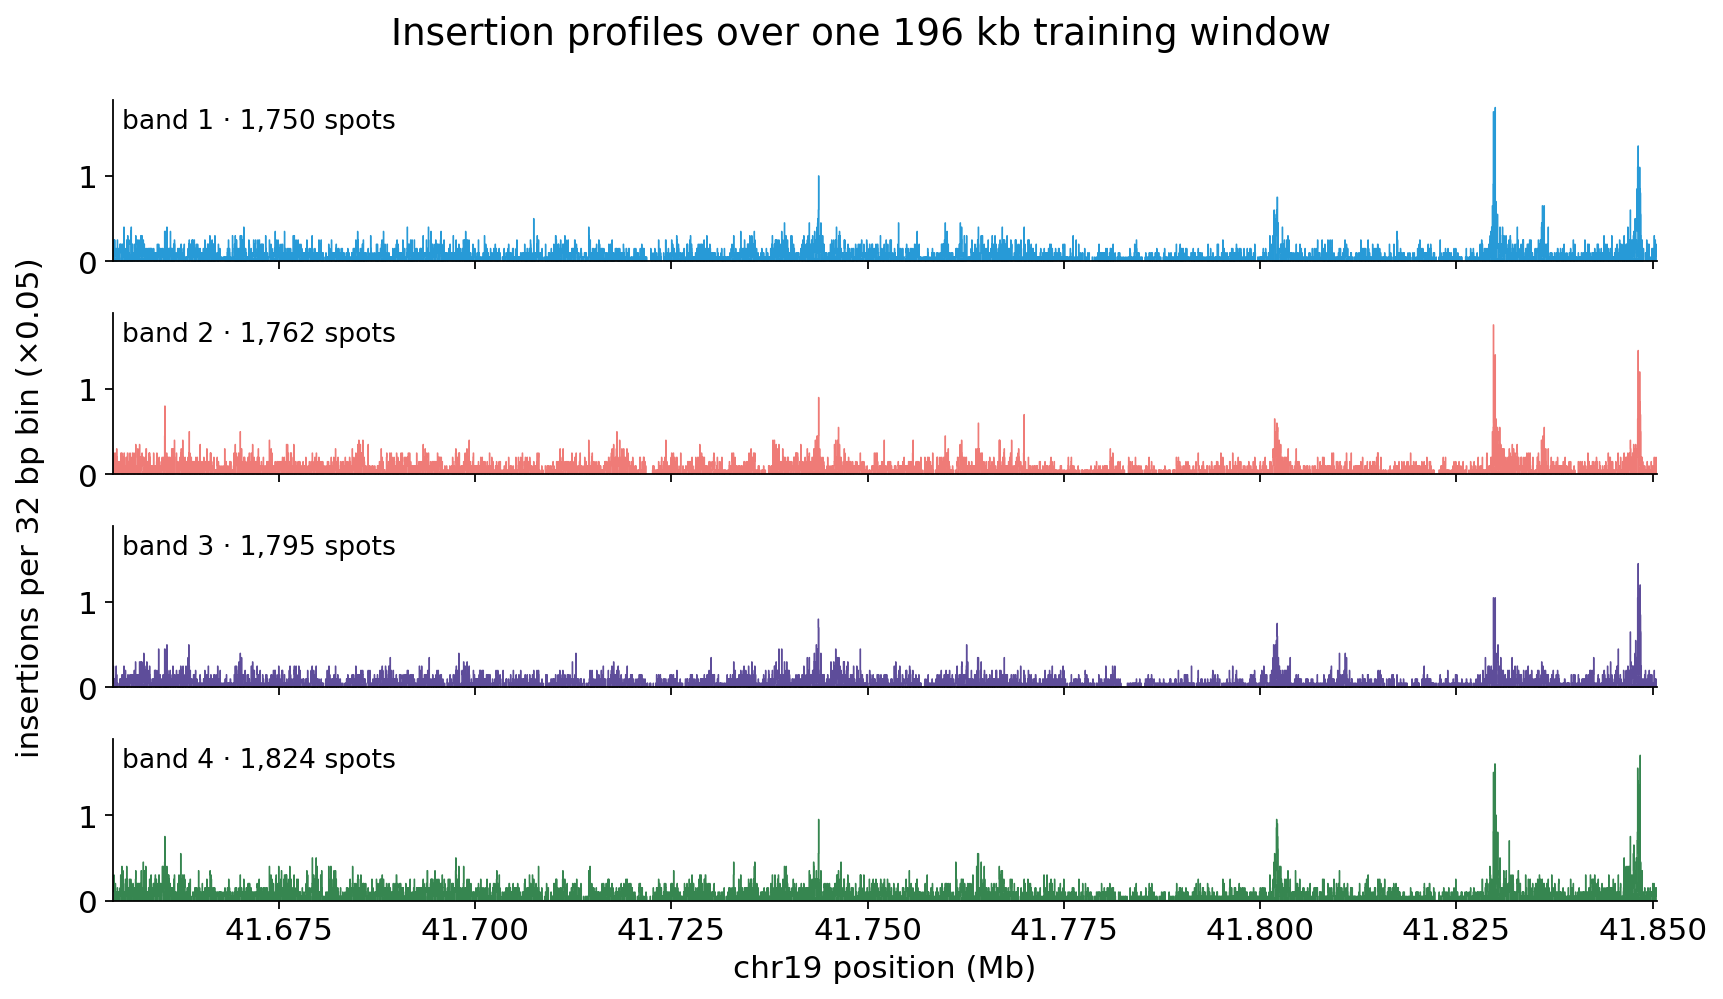

In [10]:
x = (W0 + np.arange(prof.shape[1]) * 32) / 1e6   # left edge of each bin, Mb
fig, axes = plt.subplots(4, 1, figsize=(11, 6.4), sharex=True, sharey=True)
for ax, p, nm, col, g in zip(axes, prof, names, C, groups):
    ax.fill_between(x, 0, p, step='post', color=col, lw=0)
    ax.step(x, p, where='post', color=col, lw=0.6)
    # Direct label: identity is never carried by colour alone.
    ax.annotate(f'{nm} · {len(g):,} spots', xy=(0.006, 0.95),
                xycoords='axes fraction', va='top', fontsize=12)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylim(0, prof.max() * 1.05)
# The x axis spans exactly the 196 kb window, nothing more.
axes[-1].set_xlim(W0 / 1e6, (W0 + T) / 1e6)
axes[-1].set_xlabel(f'{CHROM} position (Mb)')
fig.supylabel('insertions per 32 bp bin (×0.05)', fontsize=14)
fig.suptitle('Insertion profiles over one 196 kb training window')
plt.tight_layout(); plt.show()

## Part 5 · Folds that cannot leak

The model reads 524,288 bp to predict the central 196,608 bp. Two
adjacent target windows therefore have **inputs overlapping by 163,840 bp
per flank**. Assign windows to folds at random and a training window's
input covers a validation window's target.

`make_fold_bed` deals contiguous genomic *blocks* to folds and drops
windows within one flank of a block edge.

In [15]:
main_chroms = {k: v for k, v in chrom_sizes.items()
               if '_' not in k and k not in ('chrM',)}
folds = sb.make_fold_bed(main_chroms, WORK / 'mm10_folds.bed',
                         n_folds=8, block_windows=16, seed=0)
naive = sum(v // sb.TARGET_LENGTH for v in main_chroms.values())
print(f'{len(folds):,} windows retained of {naive:,} possible '
      f'({100 * len(folds) / naive:.0f}%), {folds["fold"].nunique()} folds')

# Verify the invariant directly: no window's input span may touch a
# target window belonging to a different fold.
leaks = 0
for c, sub in folds.groupby('chrom'):
    sub = sub.sort_values('start')
    ts, te = sub['start'].to_numpy(), sub['end'].to_numpy()
    fo = sub['fold'].to_numpy()
    for i in range(len(sub)):
        hit = (ts < te[i] + sb.FLANK) & (te > ts[i] - sb.FLANK)
        leaks += int((hit & (fo != fo[i])).sum())
print(f'cross-fold input/target overlaps: {leaks}')

11,693 windows retained of 13,854 possible (84%), 8 folds
cross-fold input/target overlaps: 0


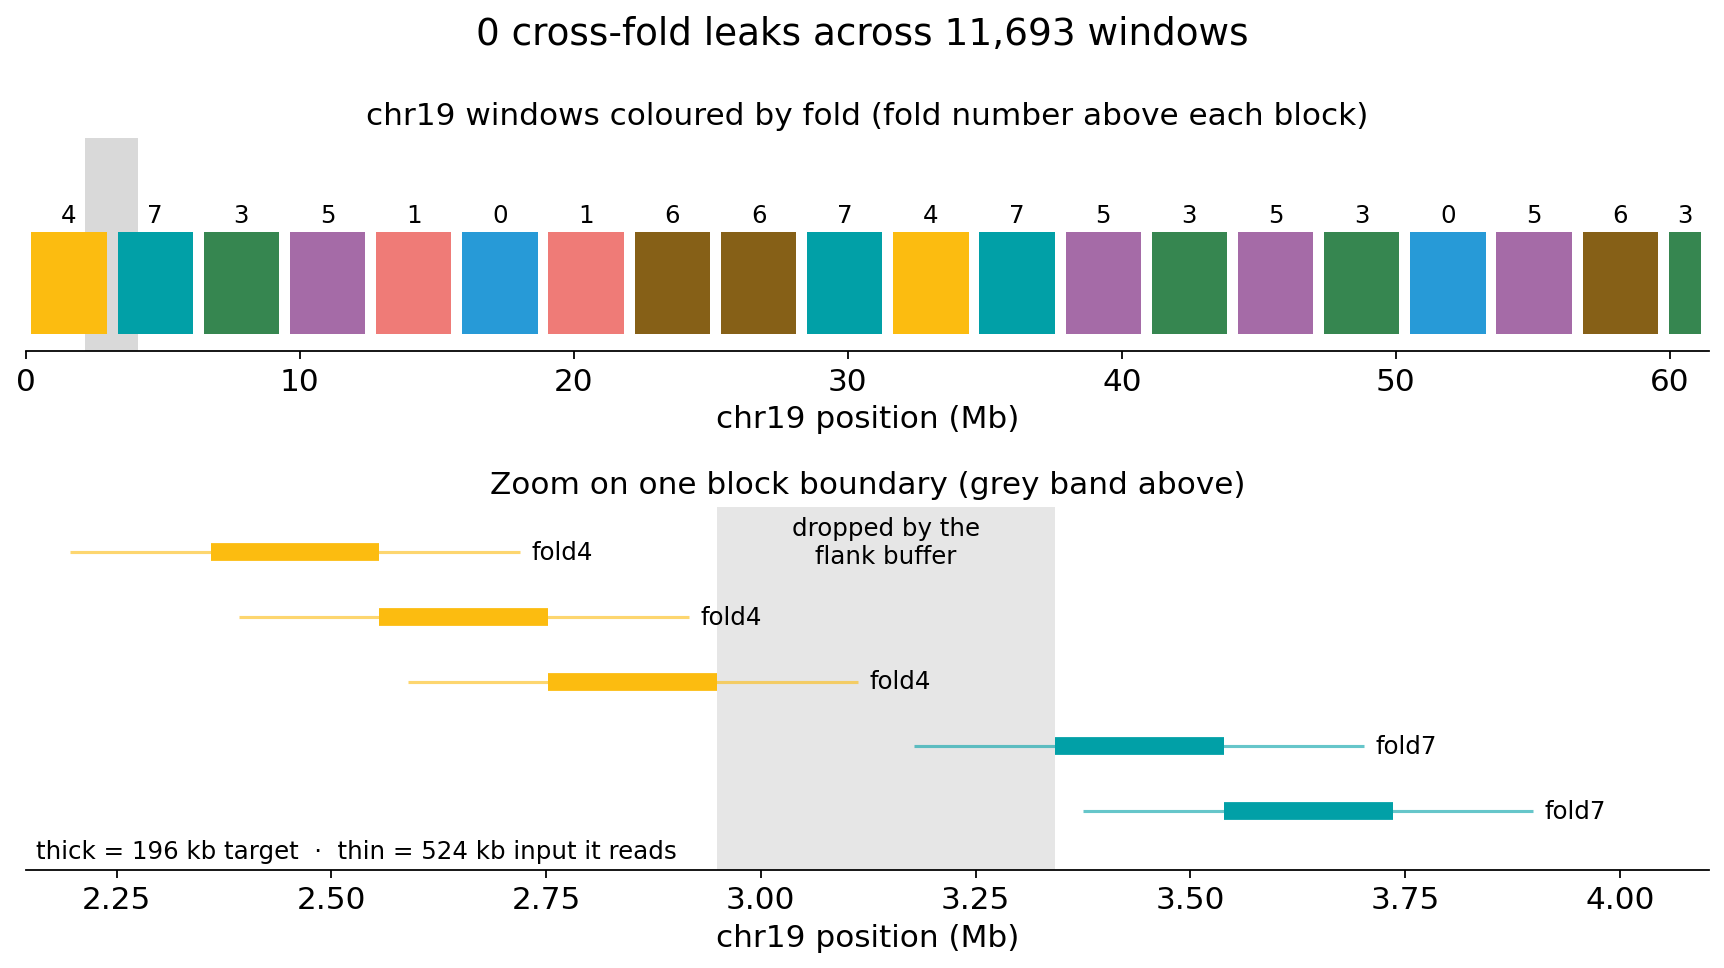

In [16]:
sub = folds[folds['chrom'] == CHROM].sort_values('start')
fold_ids = sorted(folds['fold'].unique())
# One fixed colour per fold, in fold order (FOLD_C from the setup cell).
fold_col = {f: FOLD_C[i] for i, f in enumerate(fold_ids)}
MB = 1e6

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.2),
                             gridspec_kw={'height_ratios': [1, 1.7]})

# Merge consecutive windows of one fold into a block, so each block is one
# bar with its fold number written above it (colour alone is not enough
# for eight categories).
blocks, cur = [], None
for _, r in sub.iterrows():
    if cur and r['fold'] == cur[2] and r['start'] - cur[1] <= sb.TARGET_LENGTH:
        cur[1] = r['end']
    else:
        cur = [r['start'], r['end'], r['fold']]
        blocks.append(cur)
for s, e, f in blocks:
    a1.barh(0, (e - s) / MB, left=s / MB, height=0.6,
            color=fold_col[f], edgecolor='none')
    a1.annotate(str(f).replace('fold', ''), xy=((s + e) / 2 / MB, 0.3),
                xytext=(0, 2), textcoords='offset points',
                ha='center', va='bottom', fontsize=11)
a1.set_yticks([]); a1.set_ylim(-0.4, 0.85)
a1.set_xlim(0, chrom_sizes[CHROM] / MB)
a1.set_xlabel(f'{CHROM} position (Mb)')
a1.set_title(f'{CHROM} windows coloured by fold (fold number above each block)')
a1.spines[['left', 'top', 'right']].set_visible(False)

# Zoom on one block boundary: a few windows either side, each drawn as
# its own row (target bar + the input span it actually reads) so the
# buffer between folds is legible instead of a solid colour band.
cut = sub['start'].to_numpy()
b = np.flatnonzero(np.diff(cut) > sb.TARGET_LENGTH)
bi = int(b[0]) if len(b) else len(sub) // 2
sel = sub.iloc[max(0, bi - 2): bi + 3]

gap0, gap1 = cut[bi] / MB + sb.TARGET_LENGTH / MB, cut[bi + 1] / MB
a2.axvspan(gap0, gap1, color='0.9', lw=0)
a2.annotate('dropped by the\nflank buffer', xy=((gap0 + gap1) / 2, len(sel) - 0.45),
            ha='center', va='top', fontsize=11)

for row, (_, r) in enumerate(sel.iloc[::-1].iterrows()):
    s, e = r['start'] / MB, r['end'] / MB
    col = fold_col[r['fold']]
    # Input span: what this window's 524 kb context actually covers.
    a2.plot([s - sb.FLANK / MB, e + sb.FLANK / MB], [row, row],
            color=col, lw=1.4, alpha=0.6, solid_capstyle='butt')
    # Target: the 196 kb it predicts.
    a2.plot([s, e], [row, row], color=col, lw=8, solid_capstyle='butt')
    a2.annotate(r['fold'], xy=(e + sb.FLANK / MB, row), xytext=(5, 0),
                textcoords='offset points', va='center', fontsize=11)

a2.set_ylim(-0.9, len(sel) - 0.3)
a2.set_yticks([])
# Room for the fold labels sitting past the right-hand input spans.
_lo = (sel['start'].min() - sb.FLANK) / MB
_hi = (sel['end'].max() + sb.FLANK) / MB
z0, z1 = _lo - (_hi - _lo) * 0.03, _hi + (_hi - _lo) * 0.12
a2.set_xlim(z0, z1)
a2.set_xlabel(f'{CHROM} position (Mb)')
a2.set_title('Zoom on one block boundary (grey band above)')
a2.annotate('thick = 196 kb target  ·  thin = 524 kb input it reads',
            xy=(0.006, 0.03), xycoords='axes fraction', fontsize=11)
a2.spines[['left', 'top', 'right']].set_visible(False)
# Mark the zoomed stretch on the chromosome overview.
a1.axvspan(z0, z1, color='0.85', lw=0, zorder=0)

fig.suptitle(f'{leaks} cross-fold leaks across {len(folds):,} windows')
plt.tight_layout(); plt.show()

## Part 6 · Driving upstream's model

`load_scooby` builds upstream's `Scooby` on pretrained Borzoi weights.
Use it rather than a plain `Scooby.from_pretrained`, whose model cannot be
moved to a GPU: Borzoi's relative-position tables are never materialised,
and `load_scooby` recomputes them.

Note the backbone is Borzoi's human/mouse trunk with a freshly
initialised cell-state decoder — exactly the starting point upstream
trains from. A short overfit on one window is a plumbing check, not a
result.

In [11]:
SCOOBY_SRC = os.environ.get('SCOOBY_SRC')
HAVE_UPSTREAM = bool(SCOOBY_SRC) and (pathlib.Path(SCOOBY_SRC) / 'scooby').exists()
if HAVE_UPSTREAM:
    import types
    sys.modules.setdefault('pybigtools', types.ModuleType('pybigtools'))
    sys.path.insert(0, SCOOBY_SRC)
    from scooby.data.scdata import onTheFlyMultiomeDataset
    print('upstream scooby loaded from', SCOOBY_SRC)
else:
    print('SCOOBY_SRC not set — the model section will be skipped.\n'
          'Clone https://github.com/gagneurlab/scooby and point SCOOBY_SRC at it.')

upstream scooby loaded from ~/src/scooby


In [17]:
import torch
BORZOI = os.environ.get('BORZOI_CKPT', 'johahi/borzoi-replicate-0')
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev,
      torch.cuda.get_device_name(0) if dev == 'cuda' else '')
HAVE_MODEL = HAVE_UPSTREAM and dev == 'cuda'
if not HAVE_MODEL:
    print('skipping the model section (needs upstream scooby + a GPU)')

device: cuda NVIDIA H100 80GB HBM3


In [18]:
%%time
if HAVE_MODEL:
    EMB_DIM = 8
    rng = np.random.default_rng(0)
    # A real embedding would come from epi.tl.birmt (default) / iterative_lsi / joint_embedding
    # and be exported with export_embedding(); band identity is enough to
    # exercise the conditioning here.
    emb = np.zeros((reader.n_cells, EMB_DIM), dtype=np.float32)
    emb[np.arange(reader.n_cells), band] = 1.0
    emb[:, 4:] = rng.normal(scale=0.01, size=(reader.n_cells, 4))

    # Use the same dense window as Part 4 so the figure is comparable
    # and shows real structure. Real training would iterate the fold
    # split built in Part 5; a single window here is a plumbing check.
    demo = pd.DataFrame({'chrom': [CHROM], 'start': [W0], 'end': [W0 + T],
                         'fold': ['demo']})
    ds = sb.ScoobyATACDataset(reader, FASTA, demo, emb,
                              groups=groups, rc_aug=False, seed=0)
    seq, rc, tgt, cemb = ds[0]
    # The dataset reads the same numbers the reader gave us in Part 4.
    assert np.allclose(tgt.numpy().T, prof), 'dataset/reader disagree'
    print('dataset target matches the Part 4 reader output')
    print('sequence', tuple(seq.shape), '| target', tuple(tgt.shape),
          '| cell emb', tuple(cemb.shape))

    model = sb.load_scooby(BORZOI, cell_emb_dim=EMB_DIM, n_tracks=1,
                           lora=True, train=True, device=dev)
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    tot = sum(p.numel() for p in model.parameters())
    print(f'LoRA trainable: {tr:,} / {tot:,} ({100 * tr / tot:.2f}%)')

dataset target matches the Part 4 reader output
sequence (524288, 4) | target (6144, 4) | cell emb (4, 8)


Some weights of Scooby were not initialized from the model checkpoint at johahi/borzoi-replicate-0 and are newly initialized: ['cell_state_to_conv.0.bias', 'cell_state_to_conv.0.weight', 'cell_state_to_conv.2.bias', 'cell_state_to_conv.2.weight', 'cell_state_to_conv.5.bias', 'cell_state_to_conv.5.weight', 'cell_state_to_conv.8.bias', 'cell_state_to_conv.8.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 3,564,769 || all params: 174,836,737 || trainable%: 2.0389130231823076


LoRA trainable: 3,564,769 / 174,836,737 (2.04%)
CPU times: user 2.19 s, sys: 521 ms, total: 2.71 s
Wall time: 3.53 s


In [19]:
%%time
if HAVE_MODEL:
    from scooby.utils.utils import poisson_multinomial_torch

    xb = seq.unsqueeze(0).permute(0, 2, 1).to(dev)
    yb = tgt.unsqueeze(0).to(dev)
    cb = cemb.unsqueeze(0).to(dev)

    with torch.autocast('cuda'):
        out = model(xb, cb)
    assert tuple(out.shape) == tuple(yb.shape), (out.shape, yb.shape)
    print('model output', tuple(out.shape), '== target', tuple(yb.shape))

    with torch.no_grad(), torch.autocast('cuda'):
        pred0 = model(xb, cb).float().cpu().numpy()[0]

    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                            lr=1e-3)
    losses = []
    model.train()
    for step in range(30):
        opt.zero_grad()
        with torch.autocast('cuda'):
            loss = poisson_multinomial_torch(model(xb, cb), yb, total_weight=0.2)
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'loss {losses[0]:.5f} -> {losses[-1]:.5f} '
          f'({100 * (losses[0] - losses[-1]) / losses[0]:.1f}% down)')
    print(f'peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB')

    model.eval()
    with torch.no_grad(), torch.autocast('cuda'):
        pred = model(xb, cb).float().cpu().numpy()[0]

model output (1, 6144, 4) == target (1, 6144, 4)


loss 0.63914 -> 0.52756 (17.5% down)
peak GPU memory 36.5 GiB
CPU times: user 4.62 s, sys: 540 ms, total: 5.16 s
Wall time: 5.17 s


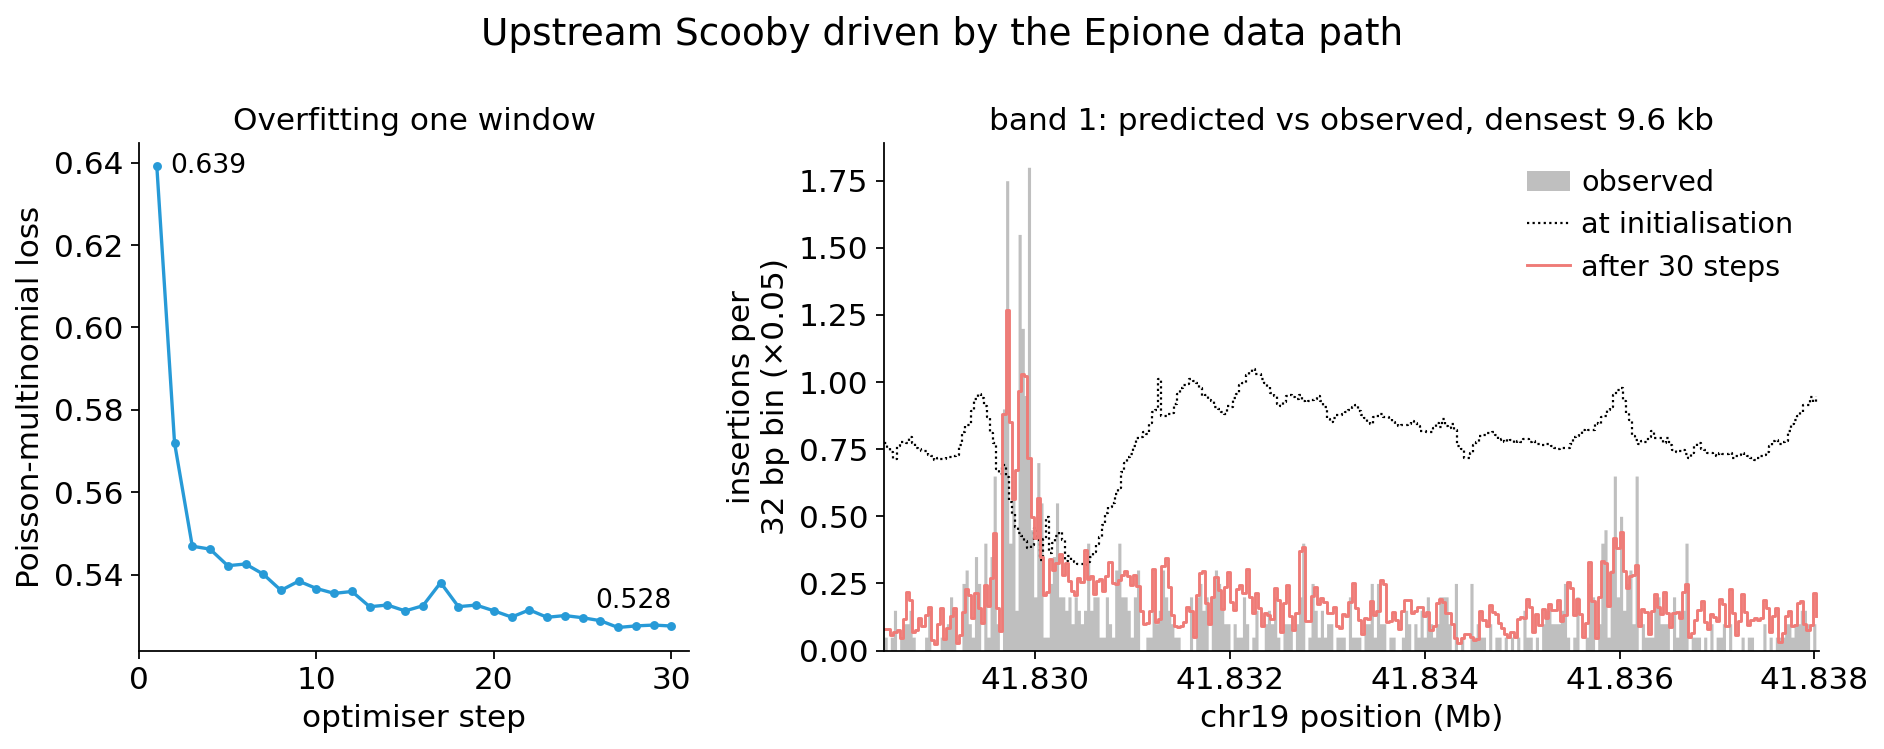

In [20]:
if HAVE_MODEL:
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8),
                                 gridspec_kw={'width_ratios': [1, 1.7]})

    steps = np.arange(1, len(losses) + 1)
    a1.plot(steps, losses, color=C[0], marker='o', ms=3)
    a1.set_xlabel('optimiser step'); a1.set_ylabel('Poisson-multinomial loss')
    a1.set_title('Overfitting one window')
    a1.set_xlim(0, len(losses) + 1)
    a1.annotate(f'{losses[0]:.3f}', xy=(1, losses[0]), xytext=(6, 0),
                textcoords='offset points', va='center', fontsize=12)
    a1.annotate(f'{losses[-1]:.3f}', xy=(len(losses), losses[-1]),
                xytext=(0, 8), textcoords='offset points', ha='right',
                fontsize=12)
    a1.spines[['top', 'right']].set_visible(False)

    # 6,144 bins do not fit on a page: zoom onto the densest 300.
    g, k = 0, 300
    obs = tgt.numpy()[:, g]
    zz = int(np.convolve(obs, np.ones(k), 'valid').argmax())
    sl = slice(zz, zz + k)
    xm = (W0 + np.arange(obs.shape[0]) * 32) / 1e6

    a2.fill_between(xm[sl], 0, obs[sl], step='post', color='0.75',
                    lw=0, label='observed')
    a2.step(xm[sl], pred0[sl, g], where='post', color='k', lw=1.0,
            ls=(0, (1, 1.5)), label='at initialisation')
    a2.step(xm[sl], pred[sl, g], where='post', color=C[1], lw=1.3,
            label=f'after {len(losses)} steps')
    a2.legend(loc='upper right', ncol=1, frameon=False, handlelength=1.5)
    a2.set_xlim(xm[sl][0], xm[sl][-1] + 32 / 1e6)
    a2.set_ylim(0, None)
    a2.set_xlabel(f'{CHROM} position (Mb)')
    a2.set_ylabel('insertions per\n32 bp bin (×0.05)')
    a2.set_title(f'{names[g]}: predicted vs observed, '
                 f'densest {k * 32 / 1e3:.1f} kb')
    a2.spines[['top', 'right']].set_visible(False)

    fig.suptitle('Upstream Scooby driven by the Epione data path')
    plt.tight_layout(); plt.show()

## Summary

| | |
|---|---|
| Sample | GSE308623 `P2S1`, mouse brain P2, spatial ATAC, mm10 |
| Spots on tissue | 7,131 of a 100×100 grid |
| Targets | read per-window from tabix; no genome-wide insertion matrix |
| Model | upstream `Scooby` on Borzoi weights, 2.04% params trainable via LoRA |
| Geometry | 524,288 bp in → 6,144 × 32 bp bins out |

**The measurement that should drive the next design decision**: a single
50 µm spot contributes about one fragment to a training window. Any
single-cell-resolution target on this data is noise, so the useful axis is
not "more resolution" but better *grouping* — by cell type after
deconvolution, by timepoint, or by spatial domain.

Next steps worth taking from here, in the order they pay off:

1. A real cell embedding — `epi.tl.birmt` (default) or `epi.tl.iterative_lsi` on the peak matrix, then
   `export_embedding(..., drop_first=True)` (LSI component 0 tracks
   sequencing depth).
2. Cell-type deconvolution against a reference atlas, so groups are
   biological rather than geometric bands.
3. Train properly on held-out folds and compare against this baseline.

Checks against upstream scooby: `tests/test_scooby_parity.py`,
`tests/test_scooby_model.py` and `tests/parity/scooby/tutorial_checks.ipynb`.